# Mineração de dados – Supermercado (Equipe 4)

Duas técnicas aplicadas sobre o **Data Warehouse** (esquema `dw`, modelo estrela):

1. **Regras de associação (Apriori)** sobre os produtos de cada cupom fiscal → *quais produtos são comprados juntos?*
2. **Agrupamento (k-means)** dos clientes por **R**ecência, **F**requência e valor **M**onetário (RFM) → *quais perfis de cliente existem?*

Processo KDD seguido: seleção (consulta no DW) → pré-processamento (limpeza já feita no ETL; filtros abaixo) → transformação (matriz cupom × produto; RFM padronizado) → mineração (Apriori; k-means) → interpretação (conclusões de negócio no fim).

Bibliotecas: `pandas`, `mlxtend` (Apriori), `scikit-learn` (k-means), `matplotlib`. Instalação: `pip install -r mineracao/requirements.txt`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psycopg2
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
DADOS = Path("dados")
DADOS.mkdir(exist_ok=True)

# Conexao com o PostgreSQL (mesmo banco do OLTP e do DW)
con = psycopg2.connect(host=os.getenv("PGHOST", "localhost"), user=os.getenv("PGUSER", "postgres"),
                       password=os.getenv("PGPASSWORD", "postgres"), dbname=os.getenv("PGDATABASE", "supermercado"))

def consulta(sql):
    with con.cursor() as cur:
        cur.execute(sql)
        colunas = [c[0] for c in cur.description]
        return pd.DataFrame(cur.fetchall(), columns=colunas)

## 1. Seleção e exportação da base

Duas bases são extraídas do DW e salvas em `mineracao/dados/` (CSV), para que a análise possa ser repetida também no Weka:

- `itens_por_cupom.csv`: uma linha por item vendido (cupom, produto, categoria);
- `clientes_rfm.csv`: uma linha por cliente com recência, frequência e valor. As versões SCD2 de um mesmo cliente são somadas pelo `id_origem`.

In [2]:
itens = consulta("""
    SELECT f.numero_cupom, p.nome AS produto, p.categoria
    FROM dw.fato_venda f
    JOIN dw.dim_produto p ON p.sk_produto = f.sk_produto
    ORDER BY f.numero_cupom
""")
itens.to_csv(DADOS / "itens_por_cupom.csv", index=False)

rfm = consulta("""
    SELECT c.id_origem AS cliente,
           MAX(c.nome) AS nome,
           (DATE '2026-11-01' - MAX(t.data))       AS recencia_dias,
           COUNT(DISTINCT f.numero_cupom)          AS frequencia,
           SUM(f.valor_total)::FLOAT               AS valor_total
    FROM dw.fato_venda f
    JOIN dw.dim_cliente c ON c.sk_cliente = f.sk_cliente
    JOIN dw.dim_tempo   t ON t.sk_tempo = f.sk_tempo
    WHERE t.data < DATE '2026-11-01'
    GROUP BY c.id_origem
""")
rfm.to_csv(DADOS / "clientes_rfm.csv", index=False)

print(f"{len(itens)} itens em {itens.numero_cupom.nunique()} cupons; {itens.produto.nunique()} produtos")
print(f"{len(rfm)} clientes com compra")
itens.head()

10009 itens em 2001 cupons; 100 produtos
200 clientes com compra


,numero_cupom,produto,categoria
0,1,Flocao de Milho 500g,Mercearia
1,1,Biscoito Recheado 130g,Matinais
2,2,Arroz Tipo 1 5kg,Mercearia
3,2,Pao Frances kg,Padaria
4,2,Manteiga 200g,Frios e Laticinios


## 2. Regras de associação (Apriori)

**Preparação:** cada cupom vira uma linha e cada produto uma coluna booleana (*one-hot*): `True` se o produto está no cupom.

**Parâmetros:** suporte mínimo **3%** (o conjunto aparece em pelo menos ~60 cupons), confiança mínima **50%** e lift > 1. O suporte de 3% elimina combinações raras e o lift > 1 mantém só as associações acima do acaso.

- **Suporte** de A→B = fração dos cupons que contêm A e B.
- **Confiança** de A→B = dos cupons com A, a fração que também tem B = suporte(A∪B) / suporte(A).
- **Lift** de A→B = confiança / suporte(B). Lift = 1 é independência; lift > 1 indica que levar A aumenta a chance de levar B.

In [3]:
cestas = pd.crosstab(itens.numero_cupom, itens.produto).astype(bool)
print("Matriz cupom x produto:", cestas.shape)

frequentes = apriori(cestas, min_support=0.03, use_colnames=True)
regras = association_rules(frequentes, metric="confidence", min_threshold=0.5)
regras = regras[regras["lift"] > 1].sort_values(["lift", "confidence"], ascending=False)

def texto(conjunto):
    return " + ".join(sorted(conjunto))

tabela = pd.DataFrame({
    "se o cliente leva": regras["antecedents"].map(texto),
    "ele tambem leva": regras["consequents"].map(texto),
    "suporte": regras["support"].round(3),
    "confianca": regras["confidence"].round(3),
    "lift": regras["lift"].round(2),
})
tabela.to_csv(DADOS / "regras_apriori.csv", index=False)
print(f"{len(frequentes)} conjuntos frequentes, {len(tabela)} regras com confianca >= 50% e lift > 1")
tabela.head(15)

Matriz cupom x produto: (2001, 100)
208 conjuntos frequentes, 528 regras com confianca >= 50% e lift > 1


,se o cliente leva,ele tambem leva,suporte,confianca,lift
62,Molho de Tomate 340g + Oleo de Soja 900ml,Arroz Tipo 1 5kg,0.034,0.861,11.48
151,Creme Dental 90g + Papel Higienico 12 rolos,Sabonete 85g,0.031,0.913,11.14
160,Escova Dental + Shampoo 350ml,Sabonete 85g,0.031,0.899,10.96
56,Macarrao Espaguete 500g + Molho de Tomate 340g,Arroz Tipo 1 5kg,0.030,0.813,10.85
157,Escova Dental + Papel Higienico 12 rolos,Sabonete 85g,0.032,0.889,10.85
148,Creme Dental 90g + Escova Dental,Sabonete 85g,0.031,0.887,10.83
154,Creme Dental 90g + Shampoo 350ml,Sabonete 85g,0.031,0.887,10.83
194,Papel Higienico 12 rolos + Shampoo 350ml,Sabonete 85g,0.031,0.887,10.83
66,Flocao de Milho 500g + Queijo Coalho kg,Carne de Sol kg,0.036,0.878,10.65
53,Feijao Carioca 1kg + Oleo de Soja 900ml,Arroz Tipo 1 5kg,0.030,0.792,10.57


**Regras simples (1 produto → 1 produto)**, mais fáceis de usar no negócio, e uma regra lida em detalhe (exemplo da questão 13 do relatório):

In [4]:
simples = regras[(regras["antecedents"].map(len) == 1) & (regras["consequents"].map(len) == 1)]
print(f"{len(simples)} regras simples")
display(tabela.loc[simples.index].head(10))

r = simples.iloc[0]
a, b = texto(r["antecedents"]), texto(r["consequents"])
print(f"Regra: {a}  =>  {b}")
print(f"  suporte   = {r['support']:.3f}  -> {r['support']*100:.1f}% de todos os cupons tem {a} e {b} juntos")
print(f"  confianca = {r['confidence']:.3f}  -> {r['confidence']*100:.0f}% de quem leva {a} tambem leva {b}")
print(f"  lift      = {r['lift']:.2f}   -> levar {a} torna {b} {r['lift']:.1f}x mais provavel do que no cupom medio")
print(f"  (sozinho, {b} aparece em {r['consequent support']*100:.1f}% dos cupons)")

51 regras simples


,se o cliente leva,ele tambem leva,suporte,confianca,lift
4,Flocao de Milho 500g,Carne de Sol kg,0.043,0.565,6.85
5,Carne de Sol kg,Flocao de Milho 500g,0.043,0.527,6.85
7,Queijo Coalho kg,Carne de Sol kg,0.045,0.552,6.70
8,Carne de Sol kg,Queijo Coalho kg,0.045,0.545,6.70
50,Shampoo 350ml,Sabonete 85g,0.041,0.546,6.66
49,Sabonete 85g,Shampoo 350ml,0.041,0.506,6.66
28,Creme Dental 90g,Sabonete 85g,0.041,0.543,6.63
27,Sabonete 85g,Creme Dental 90g,0.041,0.500,6.63
2,Arroz Tipo 1 5kg,Molho de Tomate 340g,0.040,0.540,6.55
37,Queijo Coalho kg,Flocao de Milho 500g,0.041,0.503,6.54


Regra: Flocao de Milho 500g  =>  Carne de Sol kg
  suporte   = 0.043  -> 4.3% de todos os cupons tem Flocao de Milho 500g e Carne de Sol kg juntos
  confianca = 0.565  -> 56% de quem leva Flocao de Milho 500g tambem leva Carne de Sol kg
  lift      = 6.85   -> levar Flocao de Milho 500g torna Carne de Sol kg 6.9x mais provavel do que no cupom medio
  (sozinho, Carne de Sol kg aparece em 8.2% dos cupons)


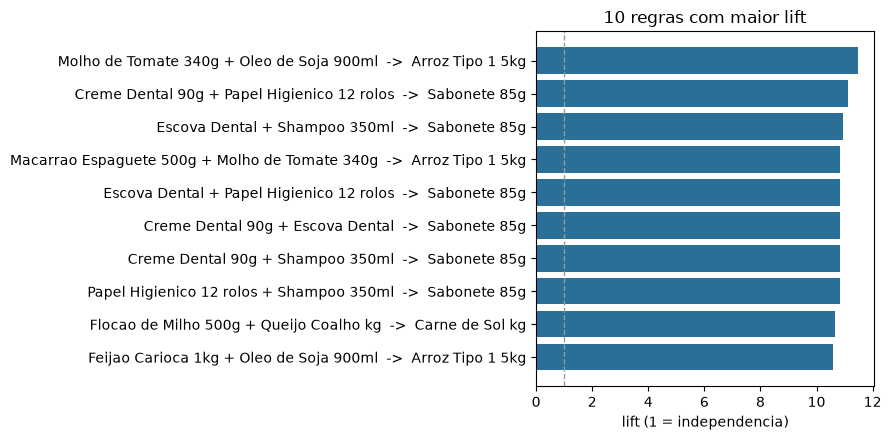

In [5]:
top = tabela.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top["se o cliente leva"] + "  ->  " + top["ele tambem leva"], top["lift"], color="#2a6f97")
ax.axvline(1, color="#999", ls="--", lw=1)
ax.set_xlabel("lift (1 = independencia)")
ax.set_title("10 regras com maior lift")
plt.tight_layout()
plt.savefig(DADOS / "regras_lift.png", dpi=120)
plt.show()

## 3. Agrupamento de clientes (k-means sobre RFM)

**Preparação:** recência (dias desde a última compra até 01/11/2026), frequência (nº de cupons) e valor total. Como o k-means usa distância euclidiana, as três variáveis são **padronizadas** (média 0, desvio 1) para que o valor em R$ não domine as outras.

**Escolha de k:** testamos k = 2 a 7 pelo método do cotovelo (inércia) e pelo coeficiente de silhueta.

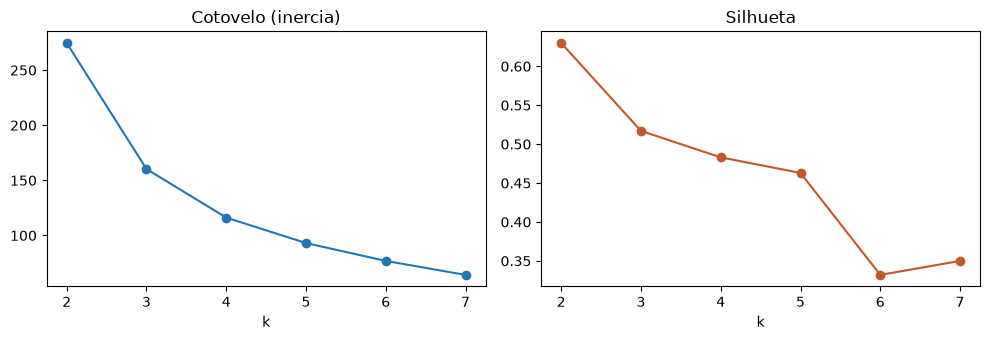

,k,inercia,silhueta
0,2,274.7,0.630
1,3,160.3,0.517
2,4,116.2,0.483
3,5,93.1,0.463
4,6,76.9,0.332
5,7,64.2,0.350


In [6]:
X = StandardScaler().fit_transform(rfm[["recencia_dias", "frequencia", "valor_total"]])

avaliacao = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    avaliacao.append({"k": k, "inercia": round(km.inertia_, 1), "silhueta": round(silhouette_score(X, km.labels_), 3)})
avaliacao = pd.DataFrame(avaliacao)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
a1.plot(avaliacao.k, avaliacao.inercia, "o-"); a1.set_title("Cotovelo (inercia)"); a1.set_xlabel("k")
a2.plot(avaliacao.k, avaliacao.silhueta, "o-", color="#c4572a"); a2.set_title("Silhueta"); a2.set_xlabel("k")
plt.tight_layout(); plt.savefig(DADOS / "kmeans_escolha_k.png", dpi=120); plt.show()
avaliacao

In [7]:
# k = 2 tem a maior silhueta, mas so separa "fieis" do resto. Escolhemos k = 4: o cotovelo achata a partir dai,
# a silhueta continua razoavel (~0,48) e 4 segmentos viram acoes de marketing diferentes.
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
rfm["grupo"] = km.labels_

perfil = (rfm.groupby("grupo")
             .agg(clientes=("cliente", "count"), recencia_media=("recencia_dias", "mean"),
                  frequencia_media=("frequencia", "mean"), valor_medio=("valor_total", "mean"),
                  valor_do_grupo=("valor_total", "sum"))
             .round(1))
perfil["% do faturamento"] = (100 * perfil.valor_do_grupo / perfil.valor_do_grupo.sum()).round(1)

# nome de negocio para cada grupo, pela ordem de valor medio e recencia
ordem = perfil.sort_values("valor_medio", ascending=False).index.tolist()
nomes = {ordem[0]: "VIP", ordem[1]: "Regulares"}
restantes = perfil.loc[ordem[2:]].sort_values("recencia_media")
nomes[restantes.index[0]] = "Esfriando"
nomes[restantes.index[1]] = "Inativos"
perfil.insert(0, "segmento", perfil.index.map(nomes))
rfm["segmento"] = rfm["grupo"].map(nomes)
rfm.to_csv(DADOS / "clientes_rfm.csv", index=False)
perfil.sort_values("valor_medio", ascending=False)

,segmento,clientes,recencia_media,frequencia_media,valor_medio,valor_do_grupo,% do faturamento
grupo,,,,,,,
2,VIP,31,32.5,24.2,4488.8,139153.0,37.4
1,Regulares,115,37.8,7.9,1439.8,165574.9,44.5
3,Esfriando,50,165.2,6.6,1293.3,64666.8,17.4
0,Inativos,4,468.8,4.0,665.8,2663.2,0.7


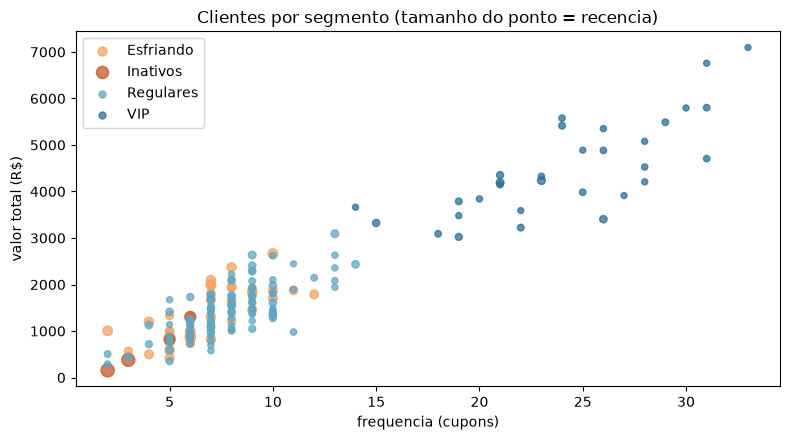

In [8]:
cores = {"VIP": "#2a6f97", "Regulares": "#61a5c2", "Esfriando": "#f4a261", "Inativos": "#c4572a"}
fig, ax = plt.subplots(figsize=(8, 4.5))
for seg, g in rfm.groupby("segmento"):
    ax.scatter(g.frequencia, g.valor_total, s=18 + g.recencia_dias / 8, alpha=.75, label=seg, color=cores[seg])
ax.set_xlabel("frequencia (cupons)"); ax.set_ylabel("valor total (R$)")
ax.set_title("Clientes por segmento (tamanho do ponto = recencia)")
ax.legend(); plt.tight_layout(); plt.savefig(DADOS / "kmeans_segmentos.png", dpi=120); plt.show()

## 4. Interpretação de negócio

As conclusões abaixo são calculadas a partir dos resultados acima (a célula seguinte imprime os números usados).

In [9]:
def regra_com(produto):
    m = regras[regras["antecedents"].map(lambda s: produto in s) | regras["consequents"].map(lambda s: produto in s)]
    return m.iloc[0] if len(m) else None

print("CONCLUSOES\n")
r = simples.iloc[0]
print(f"1) Combo de maior forca: {texto(r['antecedents'])} -> {texto(r['consequents'])} "
      f"(confianca {r['confidence']*100:.0f}%, lift {r['lift']:.1f}). Produtos com lift alto devem ficar "
      "proximos na gondola e entrar em promocoes casadas (ex.: kit), e um nao deve ser promovido sozinho "
      "quando o outro ja puxa a venda.")

grupos_cesta = {
    "churrasco": ["Picanha kg", "Carvao 3kg", "Cerveja Lata 350ml", "Linguica Toscana kg"],
    "cafe da manha": ["Pao Frances kg", "Manteiga 200g", "Cafe Torrado 250g", "Leite Integral 1L"],
    "cuscuz nordestino": ["Flocao de Milho 500g", "Queijo Coalho kg", "Carne de Sol kg"],
    "limpeza": ["Sabao em Po 1,6kg", "Amaciante 2L", "Agua Sanitaria 2L"],
    "higiene": ["Creme Dental 90g", "Escova Dental", "Sabonete 85g"],
    "feira do mes": ["Arroz Tipo 1 5kg", "Feijao Carioca 1kg", "Oleo de Soja 900ml"],
}
achados = []
for missao, prods in grupos_cesta.items():
    n = regras[regras["antecedents"].map(lambda s: bool(s & set(prods))) & regras["consequents"].map(lambda s: bool(s & set(prods)))]
    if len(n):
        achados.append(f"{missao} ({len(n)} regra{'s' if len(n) > 1 else ''}, lift max {n['lift'].max():.1f})")
print("\n2) As regras formam 'missoes de compra' bem definidas: " + "; ".join(achados) +
      ". O cliente vem ao supermercado com uma missao; o layout e os encartes podem ser organizados por missao, "
      "nao so por categoria.")

vip = perfil[perfil.segmento == "VIP"].iloc[0]
esfr = perfil[perfil.segmento == "Esfriando"].iloc[0]
inat = perfil[perfil.segmento == "Inativos"].iloc[0]
print(f"\n3) Os {int(vip.clientes)} clientes VIP ({vip.clientes/len(rfm)*100:.0f}% da base) geram "
      f"{vip['% do faturamento']:.0f}% do faturamento, com {vip.frequencia_media:.0f} cupons em media. "
      "Perder um VIP custa caro: vale um programa de fidelidade exclusivo para esse grupo.")
print(f"\n4) O segmento 'Esfriando' tem {int(esfr.clientes)} clientes que ja compraram {esfr.frequencia_media:.0f} vezes "
      f"em media, mas estao ha {esfr.recencia_media:.0f} dias sem comprar ({esfr['% do faturamento']:.0f}% do faturamento "
      "historico). Sao o alvo de uma campanha de reativacao (cupom por SMS/WhatsApp) antes de virarem Inativos "
      f"({int(inat.clientes)} clientes, {inat.recencia_media:.0f} dias sem comprar).")

CONCLUSOES

1) Combo de maior forca: Flocao de Milho 500g -> Carne de Sol kg (confianca 56%, lift 6.9). Produtos com lift alto devem ficar proximos na gondola e entrar em promocoes casadas (ex.: kit), e um nao deve ser promovido sozinho quando o outro ja puxa a venda.

2) As regras formam 'missoes de compra' bem definidas: churrasco (351 regras, lift max 9.4); cuscuz nordestino (15 regras, lift max 10.6); limpeza (2 regras, lift max 6.4); higiene (14 regras, lift max 11.1); feira do mes (12 regras, lift max 11.5). O cliente vem ao supermercado com uma missao; o layout e os encartes podem ser organizados por missao, nao so por categoria.

3) Os 31 clientes VIP (16% da base) geram 37% do faturamento, com 24 cupons em media. Perder um VIP custa caro: vale um programa de fidelidade exclusivo para esse grupo.

4) O segmento 'Esfriando' tem 50 clientes que ja compraram 7 vezes em media, mas estao ha 165 dias sem comprar (17% do faturamento historico). Sao o alvo de uma campanha de reativacao

In [10]:
con.close()